# Avocado Demand Forecasting

**Anmar Ali Al-Taani | Data science internship project**

A revised, reproducible walkthrough of an older internship project. The supplied dataset is preserved unchanged and published with provider permission, as confirmed by the author. Forecasts are historical, after August 20, 2023. This notebook uses the same implementation as `forecast.py`.

## 1. Load and inspect

Run the notebook from the repository root after installing `requirements.txt`. Dates are month/day/year. The source mixes cases and kilograms. We model case-unit sales only, for sizes 32, 48, and 60 across two companies. The complete input CSV remains unchanged.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import Image, display
from forecast import clean_data, weekly_series, run

input_path = Path('data/demand_sales_data.csv')
raw = pd.read_csv(input_path)
print(f'Original dataset: {raw.shape[0]:,} rows, {raw.shape[1]} columns')
display(raw.head())

Original dataset: 11,386 rows, 13 columns


,date,Order_ID,Company,Company_Region,Product_ID,Product,Customer_ID,Product Category01,Product Category02,Product Category03,Quantity,unit,price_per_case
0,1/1/2021,6141309,121,South,11829,AVO32CNV2,DMKUT,32.0,CNV,#2,224,case,41.0
1,1/1/2021,6377268,131,North,11541,AVO60CNV1,QPDXK,60.0,CNV,1,396,case,46.0
2,1/1/2021,6377268,131,North,11931,AVO48CNV1,QPDXK,NaN,CNV,1,148,case,45.0
3,1/1/2021,6191867,121,South,11829,AVO32CNV2,IEHDJ,32.0,CNV,#2,150,case,41.0
4,1/1/2021,6191867,121,South,11385,AVO48CNV2,IEHDJ,48.0,CNV,#2,294,case,49.0


## 2. Cleaning and calendar alignment

Exact duplicates are removed; kilogram rows are excluded from the case-demand model because no conversion is supplied. Unsupported sizes are excluded. Missing product attributes are recovered from product codes where possible. The resulting sales series use Monday-starting calendar weeks. Unrecorded weeks after a series begins would be treated as zero sales; the audit records this assumption.

In [2]:
clean, audit = clean_data(input_path)
weekly = weekly_series(clean)
print(json.dumps(audit, indent=2))
display(weekly.head())
assert weekly['week_start'].dt.weekday.eq(0).all()
assert not weekly.duplicated(['company','size','week_start']).any()

{
  "input_rows": 11386,
  "duplicate_rows_removed": 48,
  "invalid_rows_removed": 0,
  "non_case_rows_removed": 246,
  "unit_policy": "Model cases only; kilogram rows remain in the unmodified input. No conversion is assumed.",
  "non_target_or_unknown_size_rows_removed": 37,
  "clean_rows": 11055,
  "date_min": "2021-01-01",
  "date_max": "2023-08-20",
  "companies": 2
}


,company,size,week_start,quantity,imputed_zero_week
0,121,32,2020-12-28,604,False
1,121,32,2021-01-04,2116,False
2,121,32,2021-01-11,2291,False
3,121,32,2021-01-18,2167,False
4,121,32,2021-01-25,2256,False


## 3. Recursive forecasting and chronological evaluation

Each series uses four lagged quantities, the mean of those lags, and a seasonal week encoding. No current target is included as an input. Three expanding training windows forecast four weeks each, feeding predictions into later steps. Last-week and last-four-week-average baselines are evaluated at the same cutoffs. After evaluation, the Random Forest is refit on all available history.

In [3]:
audit, summary = run(input_path, Path('results'), trees=200)
display(pd.DataFrame(summary).T.round(2))

{
  "audit": {
    "input_rows": 11386,
    "duplicate_rows_removed": 48,
    "invalid_rows_removed": 0,
    "non_case_rows_removed": 246,
    "unit_policy": "Model cases only; kilogram rows remain in the unmodified input. No conversion is assumed.",
    "non_target_or_unknown_size_rows_removed": 37,
    "clean_rows": 11055,
    "date_min": "2021-01-01",
    "date_max": "2023-08-20",
    "companies": 2,
    "weekly_rows": 828,
    "zero_sales_weeks_inserted": 0,
    "forecast_rows": 24,
    "backtest_rows": 72,
    "trees": 200,
    "forecast_from": "2023-08-21",
    "forecast_to": "2023-09-11",
    "zero_sales_assumption": "Unrecorded weeks after a series begins are treated as zero sales.",
    "partial_final_week": "The final calendar week may be incomplete; no missing daily transactions can be inferred."
  },
  "backtest": {
    "random_forest": {
      "pooled_mae": 360.06878128507293,
      "pooled_rmse": 456.0979997449435
    },
    "naive_last_week": {
      "pooled_mae": 365.94

,pooled_mae,pooled_rmse
random_forest,360.07,456.10
naive_last_week,365.94,480.17
mean_last_4_weeks,334.24,408.83


## 4. Sales patterns and model comparison

Lower MAE and RMSE are better. The four-week-average baseline beats the Random Forest on both pooled MAE and RMSE. The Random Forest improves on last-week persistence. The results do not demonstrate that machine learning dominates simple methods.

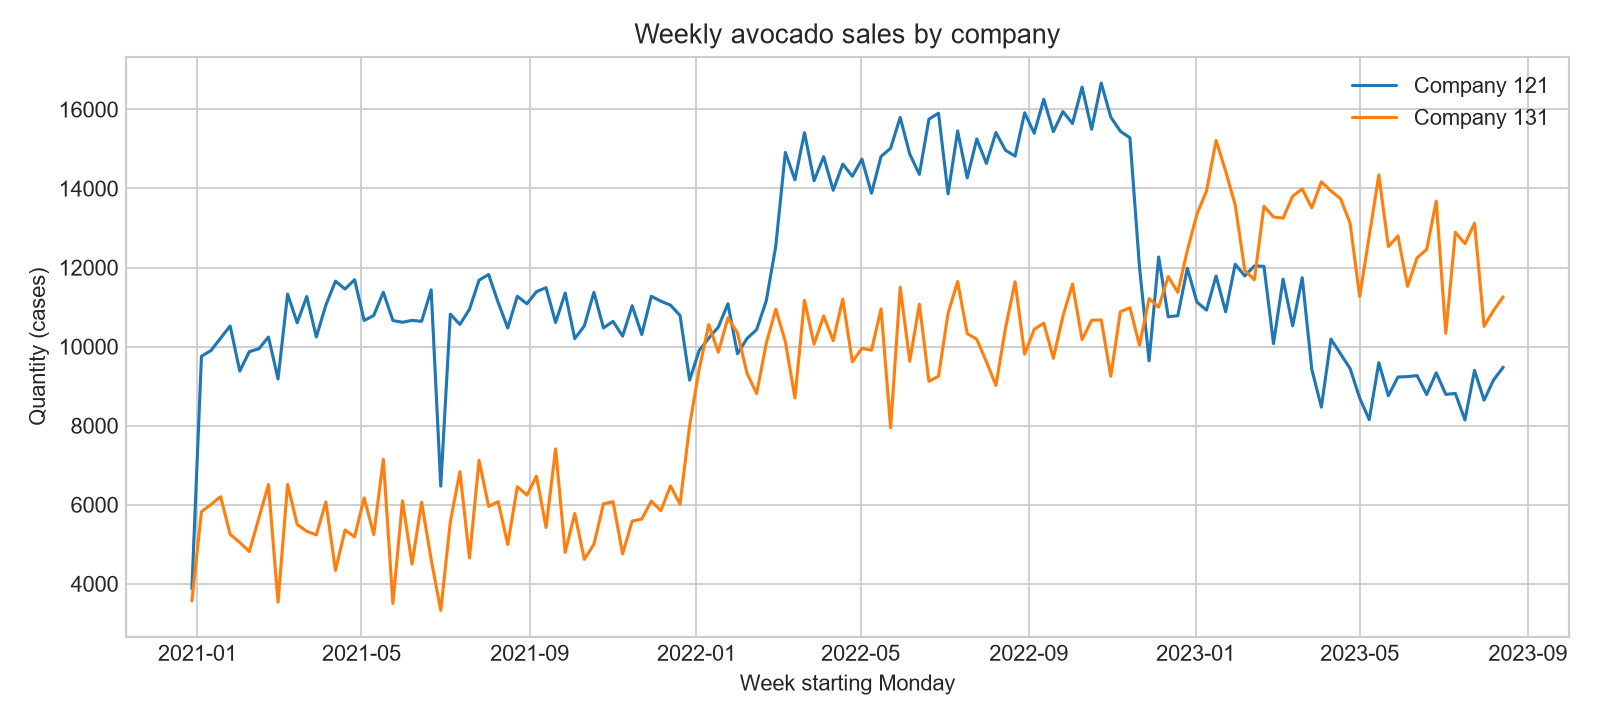

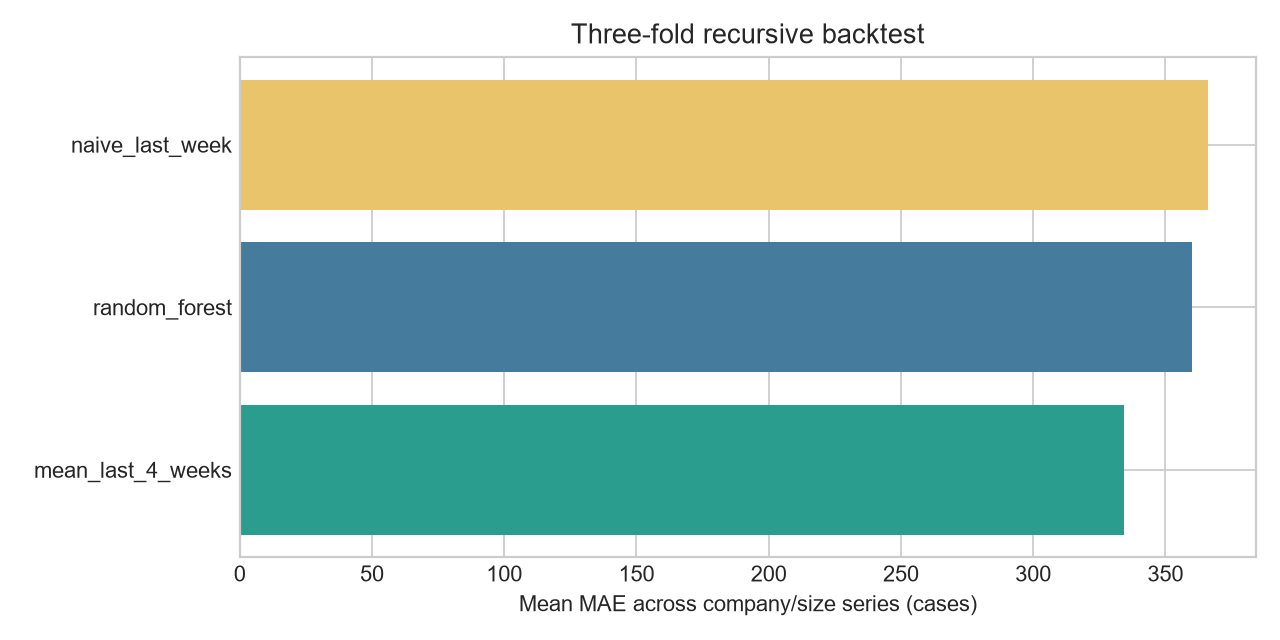

In [4]:
display(Image(filename='results/weekly_sales.png'))
display(Image(filename='results/backtest_comparison.png'))

## 5. Historical four-week forecasts

The forecasts cover the weeks beginning August 21 through September 11, 2023. They are a demonstration based on the supplied historical data, not a current operational forecast.

,company,size,horizon,week_start,forecast_quantity,naive_last_week,mean_last_4_weeks
0,121,32,1,2023-08-21,2109.37,2285.0,2403.75
1,121,32,2,2023-08-28,2232.55,2285.0,2403.75
2,121,32,3,2023-09-04,2216.74,2285.0,2403.75
3,121,32,4,2023-09-11,2370.03,2285.0,2403.75
4,121,48,1,2023-08-21,6140.18,6107.0,5944.25
5,121,48,2,2023-08-28,6176.51,6107.0,5944.25
6,121,48,3,2023-09-04,6332.06,6107.0,5944.25
7,121,48,4,2023-09-11,6527.97,6107.0,5944.25
8,121,60,1,2023-08-21,892.34,1086.0,822.00
9,121,60,2,2023-08-28,787.62,1086.0,822.00


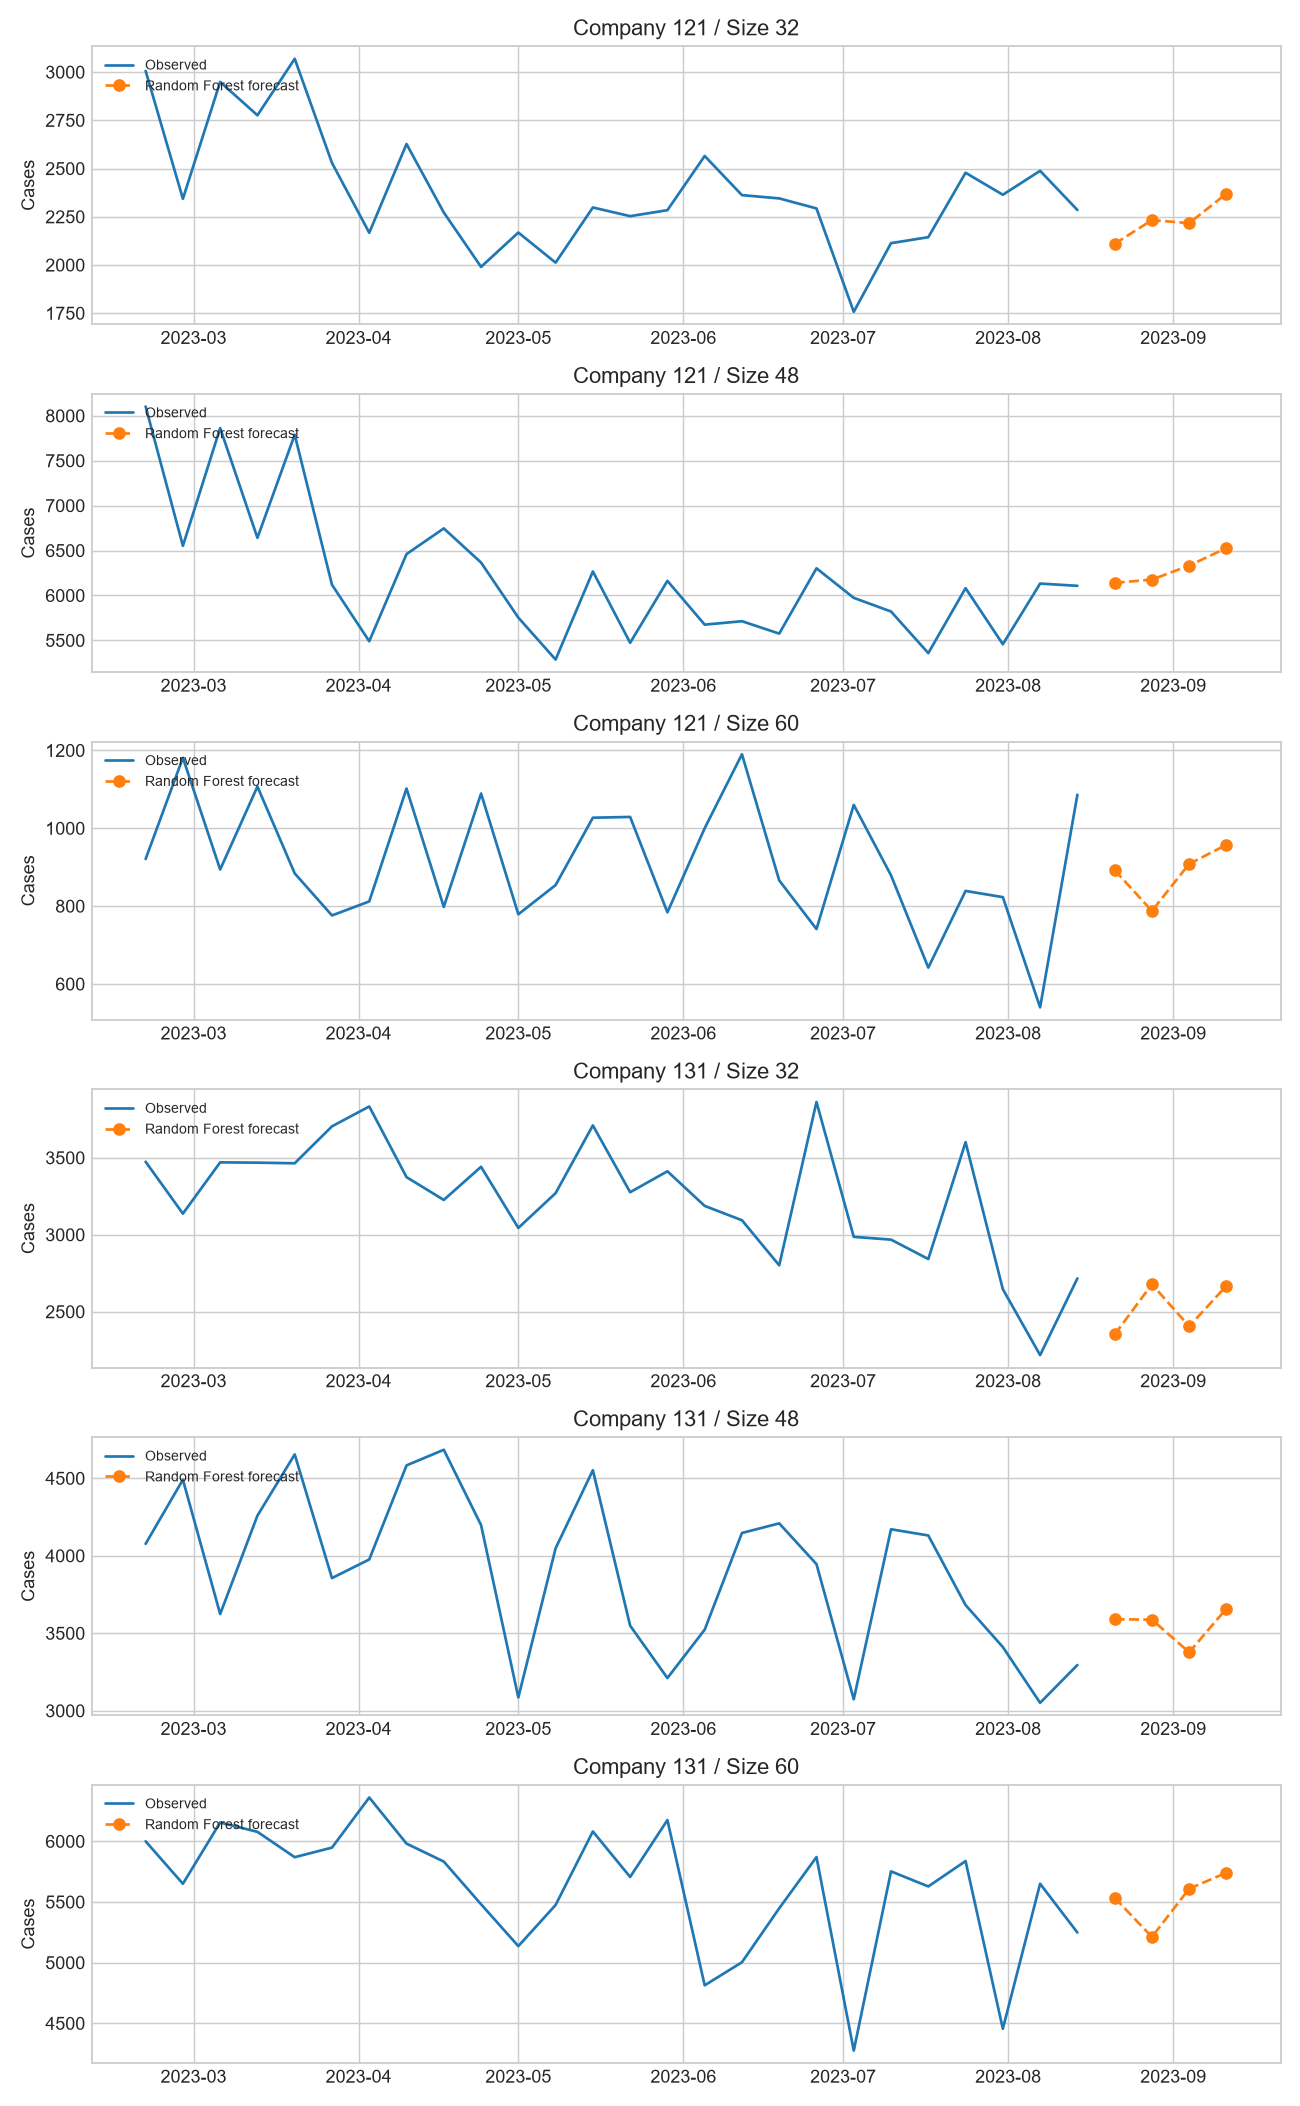

In [5]:
forecasts = pd.read_csv('results/forecasts_4_weeks.csv')
display(forecasts.round(2))
display(Image(filename='results/forecasts.png'))
assert len(forecasts) == 24
assert forecasts['forecast_quantity'].ge(0).all()

## 6. Customer order-frequency segments

Segments are simple descriptive order-count buckets. Two orders alone do not establish seasonality, and frequent purchases alone do not establish loyalty. Customer-level outputs are generated locally; only the summarized counts are displayed here.

In [6]:
segments = pd.read_csv('results/customer_segments.csv')
display(segments.groupby('segment').size().rename('company_customer_pairs').to_frame())

,company_customer_pairs
segment,
Frequent (10+),21
One order,274
Regular (3-9),1


## Conclusions and limitations

- The full input contains 11,386 rows; 11,055 target-size case-unit records remain after the documented exclusions.
- Kilogram quantities are not mixed with cases; all original records remain in the input file.
- Six company/size series produce 24 forecasts.
- The four-week-average baseline has the best pooled MAE and RMSE in these three folds.
- Evaluation covers only the final twelve weeks and is not an independent post-development test.
- Duplicate removal and zero-sales assumptions should be validated with the data owner before operational use.
- No prediction intervals, external demand drivers, production deployment, or business-impact claims are included.
- The revised workflow fixes target leakage, calendar boundaries, mixed units, recursive evaluation, and final retraining in the earlier drafts.